# Set 10: EDA + SOM Clustering

**Q1 → Exp 1A / 1B** · **Q2 → Exp 8** (SOM)

Datasets: Q1 `Solar.csv`, Q2 `IRIS.csv`. The SOM needs `pip install sklearn-som` if a lab PC doesn't have it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")      # hides library warnings so the output stays clean

---
## Question 1

### Q1.1 Read the data

In [2]:
df = pd.read_csv("data/Solar.csv")
print(df.shape)
df.head()

(228, 7)


,Latitude,Longitude,Altitude,min Temo,Max Temp,Sunshine Hour,Solar Radiation
0,34.08,74.79,1730,-0.9,4.3,0.450000,0
1,34.08,74.79,1730,-0.2,7.6,0.464286,0
2,34.08,74.79,1730,2.6,14.2,0.521429,0
3,34.08,74.79,1730,1.8,8.1,0.542857,0
4,34.08,74.79,1730,7.5,20.4,0.628571,0


### Q1.2 5-number summary of the numerical columns, correlated with a box plot

     Latitude  Longitude  Altitude  min Temo  Max Temp  Sunshine Hour  \
min      8.28      72.15       2.0      -0.9       4.3       0.428571   
25%     15.49      73.81       7.0      19.0      27.9       0.605357   
50%     21.09      77.42      81.0      23.8      29.9       0.678571   
75%     23.35      83.14     536.0      26.2      32.0       0.742857   
max     34.08      92.72    1730.0      29.7      41.1      11.000000   

     Solar Radiation  
min              0.0  
25%              0.0  
50%              0.5  
75%              1.0  
max              1.0  


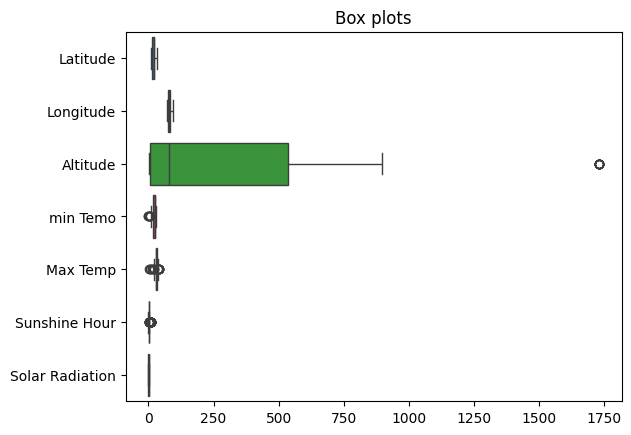

In [3]:
num = df.select_dtypes("number")
print(num.describe().loc[["min", "25%", "50%", "75%", "max"]])   # 5-number summary of every numeric column

sns.boxplot(data=num, orient="h")
plt.title("Box plots")
plt.show()

**Correlate with the box plot:** left edge of the box = 25%, middle line = 50% (median), right edge = 75%, whiskers reach towards min and max, and dots beyond the whiskers are outliers. Altitude has much bigger numbers than the rest, which is exactly why Q1.3 scales the data.

### Q1.3 Scaling with StandardScaler

In [4]:
from sklearn.preprocessing import StandardScaler

num = df.select_dtypes("number")
scaled = pd.DataFrame(StandardScaler().fit_transform(num), columns=num.columns)
print(scaled.describe().loc[["mean", "std"]].round(2))      # every column now has mean 0, std 1
scaled.head()

      Latitude  Longitude  Altitude  min Temo  Max Temp  Sunshine Hour  \
mean       0.0       -0.0      -0.0       0.0      -0.0            0.0   
std        1.0        1.0       1.0       1.0       1.0            1.0   

      Solar Radiation  
mean              0.0  
std               1.0  


,Latitude,Longitude,Altitude,min Temo,Max Temp,Sunshine Hour,Solar Radiation
0,2.322946,-0.701343,3.294297,-3.998271,-5.303794,-0.488058,-1.0
1,2.322946,-0.701343,3.294297,-3.875781,-4.617952,-0.482631,-1.0
2,2.322946,-0.701343,3.294297,-3.385821,-3.246267,-0.460919,-1.0
3,2.322946,-0.701343,3.294297,-3.525810,-4.514036,-0.452777,-1.0
4,2.322946,-0.701343,3.294297,-2.528391,-1.957714,-0.420210,-1.0


### Q1.4 Skewness with distribution plots: right, left and no skew

Latitude           0.11
Longitude          0.75
Altitude           1.89
min Temo          -1.40
Max Temp          -1.59
Sunshine Hour      2.24
Solar Radiation    0.00
dtype: float64

Right skew (> 0.5): ['Longitude', 'Altitude', 'Sunshine Hour']
Left skew (< -0.5): ['min Temo', 'Max Temp']
No skew  (-0.5 to 0.5): ['Latitude', 'Solar Radiation']


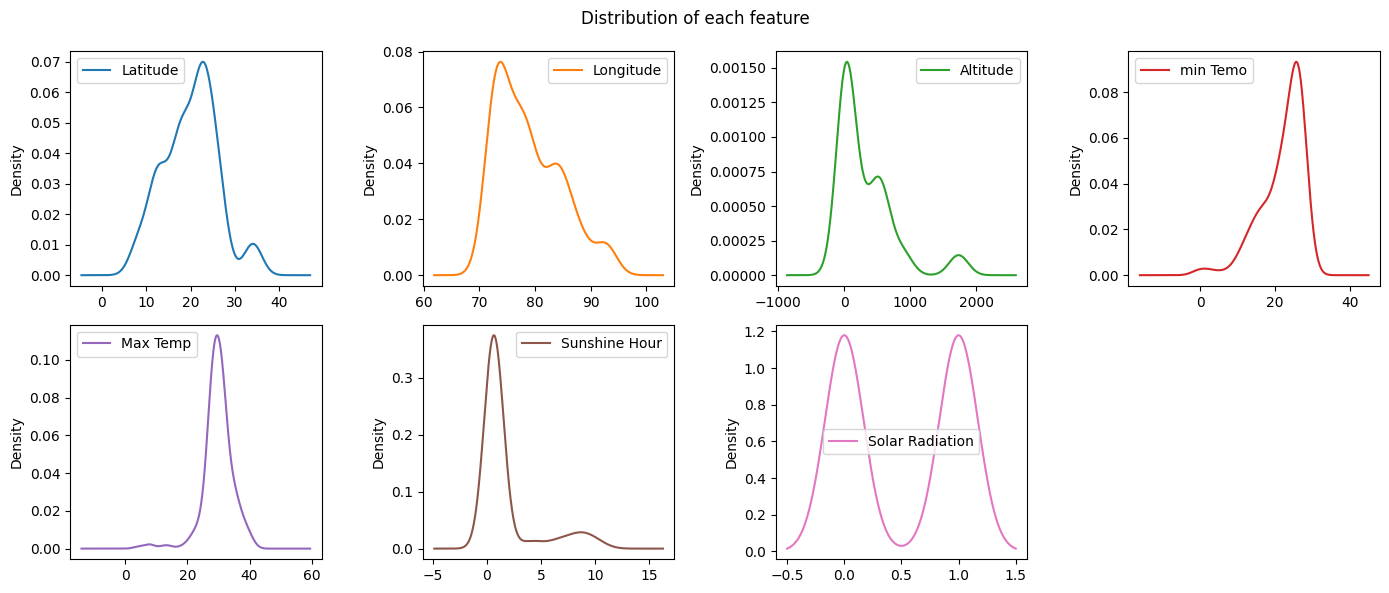

In [5]:
num = df.select_dtypes("number")
skew = num.skew()
print(skew.round(2))
print("\nRight skew (> 0.5):", list(skew[skew > 0.5].index))
print("Left skew (< -0.5):", list(skew[skew < -0.5].index))
print("No skew  (-0.5 to 0.5):", list(skew[skew.abs() <= 0.5].index))

num.plot(kind="kde", subplots=True, layout=(-1, 4), figsize=(14, 6), sharex=False, title="Distribution of each feature")
plt.tight_layout()
plt.show()

Right skew = long tail on the right (mean > median). Left skew = long tail on the left (mean < median).

### Q1.5 Z-score normalisation of a numerical feature (Python code)

In [6]:
col = "Max Temp"
df[col + "_z"] = (df[col] - df[col].mean()) / df[col].std()     # z = (x - mean) / std
df[[col, col + "_z"]].head()

,Max Temp,Max Temp_z
0,4.3,-5.292150
1,7.6,-4.607813
2,14.2,-3.239140
3,8.1,-4.504126
4,20.4,-1.953416


---
## Question 2

### Q2.1 Read the data and preprocess

In [7]:
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/IRIS.csv")
X = StandardScaler().fit_transform(df.drop(columns="Species"))   # clustering never sees the answer column
print(X.shape)

(150, 4)


### Q2.2 SOM clustering into N clusters

In [8]:
from sklearn_som.som import SOM

n = 3                                    # N = number of clusters we want
som = SOM(m=1, n=n, dim=X.shape[1], lr=1, sigma=0.5, random_state=42)   # a 1 x n grid = n clusters
som.fit(X, epochs=50, shuffle=True)      # train the map
labels = som.predict(X)                  # cluster number of every row
print("Points in each cluster:", np.bincount(labels))

Points in each cluster: [44 49 57]


A SOM with a **1 x n** grid has n neurons, and every point goes to its closest neuron, so we get **n clusters**.

### Q2.3 Measure performance with Silhouette and DB score

In [9]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

print("Silhouette (higher better):", round(silhouette_score(X, labels), 4))
print("DB score   (lower better) :", round(davies_bouldin_score(X, labels), 4))

# try other values of n and compare
rows = []
for k in range(2, 7):
    s = SOM(m=1, n=k, dim=X.shape[1], lr=1, sigma=0.5, random_state=42)
    s.fit(X, epochs=50, shuffle=True)
    lab = s.predict(X)
    rows.append([k, silhouette_score(X, lab), davies_bouldin_score(X, lab)])
scores = pd.DataFrame(rows, columns=["n", "Silhouette (higher better)", "DB (lower better)"])
scores.round(4)

Silhouette (higher better): 0.456
DB score   (lower better) : 0.8256


,n,Silhouette (higher better),DB (lower better)
0,2,0.5818,0.5933
1,3,0.4560,0.8256
2,4,0.4127,0.9235
3,5,0.3825,1.0051
4,6,0.3266,1.0508


n = 2 gets the best scores because setosa is far away and the other two species overlap. n = 3 matches the 3 real species, so we keep n = 3 for the plot.

### Q2.4 Print and plot the cluster centroids and labels for n clusters

Centroids:
 [[-0.223 -0.973  0.224  0.148]
 [-0.952  0.847 -1.232 -1.187]
 [ 0.985 -0.004  0.884  0.897]]
Labels: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 1 2 2 2 0 2 0 2 0 2 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 2 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 2 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 2 2 2 2 2 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 0 2 2 2 2 2 2 2 0 2 2 2 0 2
 2 2]


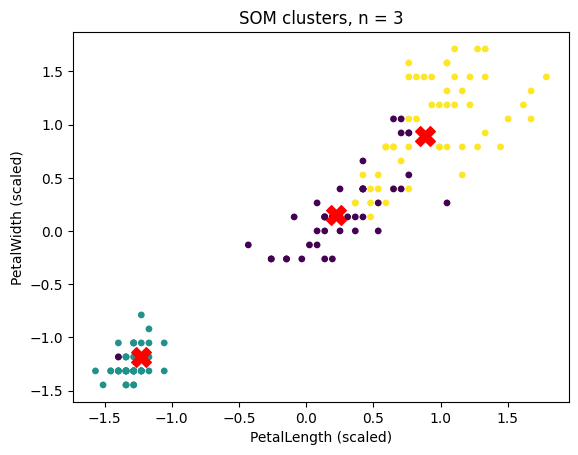

In [10]:
centroids = som.weights                  # each neuron's weights = that cluster's centroid
print("Centroids:\n", centroids.round(3))
print("Labels:", labels)

plt.scatter(X[:, 2], X[:, 3], c=labels, s=15)
plt.scatter(centroids[:, 2], centroids[:, 3], c="red", marker="X", s=200)
plt.xlabel("PetalLength (scaled)")
plt.ylabel("PetalWidth (scaled)")
plt.title(f"SOM clusters, n = {n}")
plt.show()